In [1]:
# conda env 'at3d_pure_k9'
from pathlib import Path
PROJECT_ROOT = Path().resolve().parent
INTERIM_DATA = PROJECT_ROOT / 'data' / 'interim'

import sys
sys.path.append(str(PROJECT_ROOT))

import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
from src.utils.util import load_sensor_dict
from src.utils.util import save_sensor_dict
from scipy.interpolate import CubicSpline
from scipy.optimize import minimize

In [2]:
## INPUT
lut_file = PROJECT_ROOT / 'NK1990_1D_Retrieval' / 'LUT_V04.nc'
obs_file = INTERIM_DATA / 'AT3D_OBS_CAMP2Ex_RF17_default.nc'
rte_grid_file = INTERIM_DATA / 'RTG_default.nc'

## OUTPUT
out_file = INTERIM_DATA / 'TAU1D_LUT_V04_AT3D_OBS_CAMP2Ex_RF17_default.nc'

In [3]:
rte_grid = xr.load_dataset(rte_grid_file)
obs = load_sensor_dict(obs_file)
I = obs['MISR']['sensor_list'][4].I.data
LUT = xr.load_dataset(lut_file)
assert np.all(np.diff(LUT.I.data) > 0), "LUT BRF not monotonic"

In [4]:
def cost_func(taus, obs, LUT_cs):
    resid = obs - LUT_cs(taus)
    F = np.matmul(resid.T, resid)
    J = 2 * resid * LUT_cs(taus, 1)
    return F, J

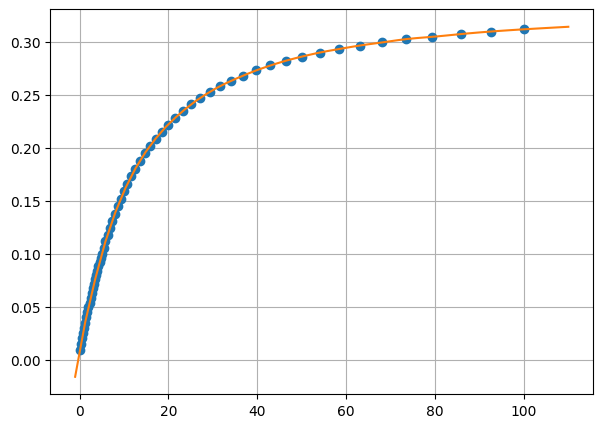

In [5]:
LUT_cs = CubicSpline(LUT.tau.data, LUT.I.data, bc_type='not-a-knot')
f, ax = plt.subplots(1, 1, figsize=(7, 5))
xs = np.linspace(-1, 110)
ax.plot(LUT.tau.data, LUT.I.data, 'o')
ax.plot(xs, LUT_cs(xs))
ax.grid()

In [6]:
tau0 = np.ones(I.shape)*1
LUT_cs = CubicSpline(LUT.tau.data, LUT.I.data, bc_type='not-a-knot')
fun = lambda x:cost_func(x, I, LUT_cs)
result = minimize(
    fun,
    tau0,
    jac=True,
    method='L-BFGS-B',
    options={'maxiter': 100, 'maxfun': 1000, 'disp': True, 'maxls': 100},
    bounds = [(0, 100)]*len(tau0)
)
obs['MISR']['sensor_list'][4]['tau'] = (['nrays'], result.x)

RUNNING THE L-BFGS-B CODE

           * * *

Machine precision = 2.220D-16
 N =         9127     M =           10

At X0         0 variables are exactly at the bounds

At iterate    0    f=  3.45526D+00    |proj g|=  4.77646D-03



   evaluations in the last line search.  Termination
   may possibly be caused by a bad search direction.



At iterate    1    f=  3.45526D+00    |proj g|=  4.77646D-03

           * * *

Tit   = total number of iterations
Tnf   = total number of function evaluations
Tnint = total number of segments explored during Cauchy searches
Skip  = number of BFGS updates skipped
Nact  = number of active bounds at final generalized Cauchy point
Projg = norm of the final projected gradient
F     = final function value

           * * *

   N    Tit     Tnf  Tnint  Skip  Nact     Projg        F
 9127      1     27      1     0     0   4.776D-03   3.455D+00
  F =   3.4552595286021806     

CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH             


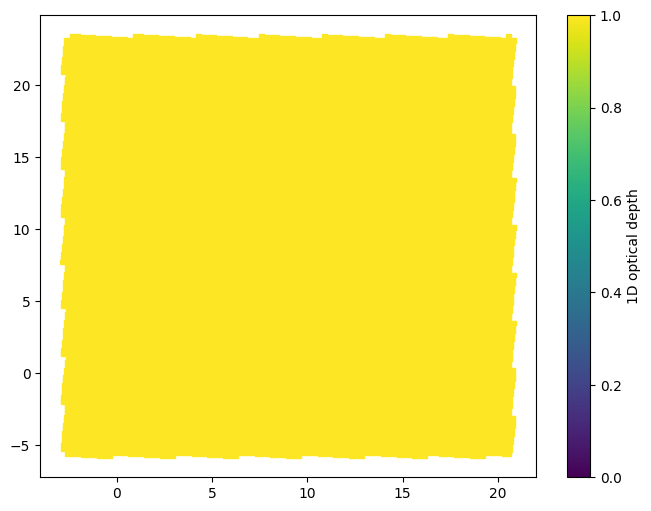

In [7]:
cam = obs['MISR']['sensor_list'][4]
f, ax = plt.subplots(1, 1, figsize=(8,6))
# c = ax.scatter(cam.ray_x, cam.ray_y, c=cam.tau, marker='s', s=10, norm=colors.LogNorm(vmin=0.1, vmax=10))
c = ax.scatter(cam.ray_x, cam.ray_y, c=cam.tau, marker='s', s=10, vmin=0.0, vmax=None)
plt.colorbar(c, label='1D optical depth')